In [24]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import ast
import seaborn as sns
from adjustText import adjust_text

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x : ast.literal_eval(x) if pd.notna(x) else x)

C:\Users\prajw\AppData\Local\Temp\ipykernel_24292\2316144345.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(job_list, tick_labels=job_titles, vert=False)


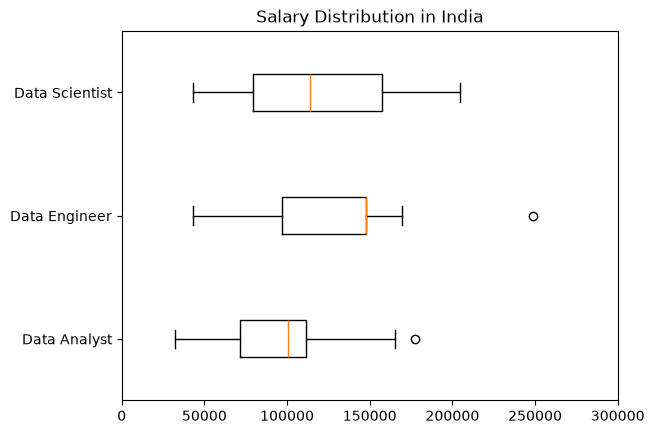

In [17]:
job_titles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

df_ind = df[(df['job_title_short'].isin(job_titles)) & (df['job_country'] == 'India')].copy()
df_ind = df_ind.dropna(subset=['salary_year_avg'])

job_list = [
    df_ind[df_ind['job_title_short'] == job_title]['salary_year_avg']
    for job_title in job_titles
]

plt.boxplot(job_list, tick_labels=job_titles, vert=False)
plt.title('Salary Distribution in India')
plt.xlim(0, 300000)
plt.show()

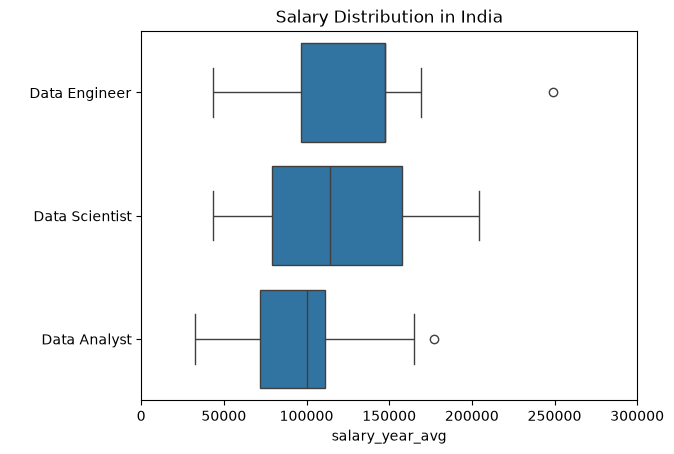

In [23]:
sns.boxplot(data=df_ind, x='salary_year_avg', y='job_title_short')
plt.title('Salary Distribution in India')
plt.ylabel(' ')
plt.xlim(0, 300000)
plt.show()